# Exercice 1 — Similarité basée sur les couleurs dominantes

## Objectif

Représenter chaque image du dossier `seance 4/Couleur/` par ses **couleurs dominantes**, puis calculer une **matrice de similarité** entre toutes les images.

Une image est ici résumée par un petit nombre de couleurs et par leur **proportion** dans l'image. Deux images se ressemblent si elles sont composées des mêmes couleurs, dans des proportions comparables.

## Principe

1. On **élimine le fond** de l'image (les objets sont photographiés sur un fond sombre commun).
2. On **quantifie** les couleurs des pixels de l'objet (pas de 32 par canal).
3. On garde les couleurs qui couvrent ensemble **90 %** des pixels de l'objet.
4. On définit une **distance** entre deux ensembles de couleurs, même si leur nombre est différent.
5. On calcule la **matrice de similarité** et on l'analyse.

## Plan du notebook

| Étape | Contenu |
|---|---|
| 1 | Chargement des images et masque du fond |
| 2 | Extraction des couleurs dominantes |
| 3 | Mesure de distance entre deux images |
| 4 | Matrice de similarité |
| 5 | Visualisation et classement |
| 6 | Analyse et discussion |


In [15]:
import os
import glob
import csv

import numpy as np
import cv2
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
# Le notebook doit fonctionner que le dossier courant soit "seance 4" ou la
# racine du dépôt : on détecte automatiquement le bon chemin de base.
BASE = "seance 4" if os.path.isdir("seance 4") else "."

DOSSIER_IMAGES = os.path.join(BASE, "Couleur")
DOSSIER_RESULTATS = os.path.join(BASE, "resultats")
os.makedirs(DOSSIER_RESULTATS, exist_ok=True)

# Paramètres de la méthode
PAS_QUANTIFICATION = 32     # pas de quantification RGB (8 niveaux par canal)
COUVERTURE = 0.90           # on garde les couleurs couvrant 90 % des pixels
K_MAX = 10                  # nombre maximum de couleurs dominantes
TOLERANCE_FOND = 20         # tolérance de distance RGB pour le masque du fond

# Liste des images
chemins = sorted(glob.glob(os.path.join(DOSSIER_IMAGES, "*.png")))
noms_images = [os.path.basename(c) for c in chemins]

print(f"{len(chemins)} images trouvées dans '{DOSSIER_IMAGES}' :")
for nom in noms_images:
    print("   -", nom)


12 images trouvées dans '.\Couleur' :
   - obj14__275.png
   - obj14__330.png
   - obj14__60.png
   - obj16__245.png
   - obj16__5.png
   - obj16__70.png
   - obj1__180.png
   - obj1__40.png
   - obj1__95.png
   - obj27__125.png
   - obj27__190.png
   - obj27__275.png


## Étape 1 — Chargement et masque du fond

Les 12 images sont des photographies 128×128 d'objets posés sur un **fond sombre commun** (couleur ≈ `[25, 25, 25]`).

Si l'on ne retire pas ce fond, **toutes les images se ressemblent** (elles partagent la même grande zone sombre) et la comparaison n'a plus de sens. Il faut donc ne garder que les pixels appartenant réellement à l'objet.

### Méthode retenue

1. On estime la **couleur du fond** comme la couleur la plus fréquente sur la **bordure** de l'image (les objets sont centrés, la bordure est presque toujours du fond).
2. Un pixel est considéré comme **objet** si sa distance euclidienne RGB à la couleur du fond est **supérieure à une tolérance** (20).

### Pourquoi ne pas réutiliser le seuil fixe de la séance 3 ?

La séance 3 utilisait un seuil fixe (intensité < 40 sur les 3 canaux). Ce seuil est risqué ici : certains objets sombres (la boîte de café, les zones d'ombre du chat) ont des pixels qui pourraient être **supprimés à tort**. La comparaison à la couleur réelle du fond est plus fiable.

**Vérification visuelle obligatoire** : on affiche ci-dessous l'image et son masque pour contrôler qu'aucune partie de l'objet n'est éliminée.


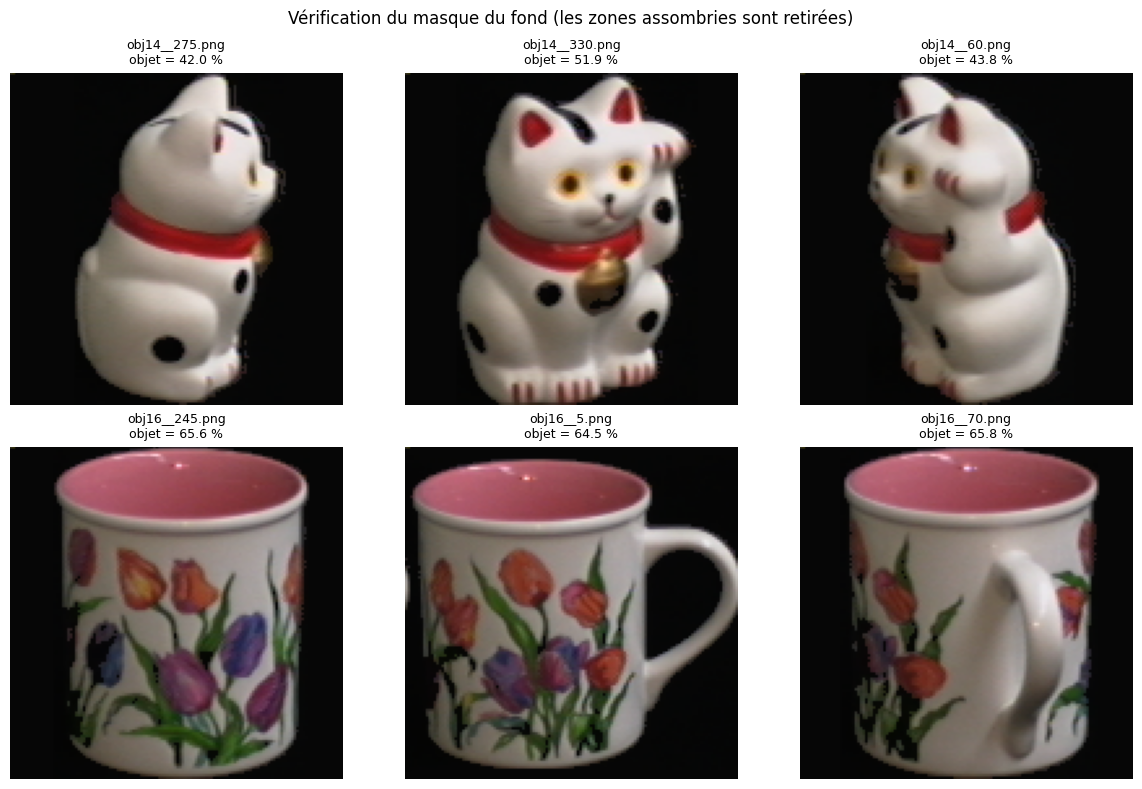

In [10]:
def charger_image(chemin):
    """Charge une image avec OpenCV et la convertit en RGB (OpenCV lit en BGR)."""
    bgr = cv2.imread(chemin)
    if bgr is None:
        raise FileNotFoundError(f"Image introuvable : {chemin}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def couleur_fond(rgb):
    """Estime la couleur du fond : couleur la plus fréquente sur la bordure."""
    bordure = np.concatenate([rgb[0, :], rgb[-1, :], rgb[:, 0], rgb[:, -1]])
    valeurs, comptes = np.unique(bordure.reshape(-1, 3), axis=0, return_counts=True)
    return valeurs[np.argmax(comptes)]


def masque_objet(rgb, tolerance=TOLERANCE_FOND):
    """Masque booléen : True pour les pixels d'objet (éloignés de la couleur du fond)."""
    fond = couleur_fond(rgb)
    distance = np.linalg.norm(rgb.astype(float) - fond.astype(float), axis=2)
    return distance > tolerance


# --- Vérification visuelle du masque sur 6 images ---
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, chemin in zip(axes.ravel(), chemins[:6]):
    rgb = charger_image(chemin)
    masque = masque_objet(rgb)

    # Superposition : les pixels d'objet sont laissés tels quels,
    # les pixels de fond sont assombris (pour bien voir ce qui est retiré).
    apercu = rgb.copy()
    apercu[~masque] = (apercu[~masque] * 0.25).astype(np.uint8)

    ax.imshow(apercu)
    ax.set_title(f"{os.path.basename(chemin)}\nobjet = {masque.mean() * 100:.1f} %",
                 fontsize=9)
    ax.axis("off")

plt.suptitle("Vérification du masque du fond (les zones assombries sont retirées)")
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_RESULTATS, "ex1_masque_fond.png"), dpi=120)
plt.show()


## Étape 2 — Extraction des couleurs dominantes

### Principe

1. **Quantification RGB** : chaque canal est arrondi au multiple de `PAS_QUANTIFICATION = 32` (`0, 32, 64, …, 224`), soit 8 niveaux par canal. Deux couleurs proches tombent ainsi dans la même case, ce qui évite des milliers de couleurs quasi identiques.
2. On **compte** les pixels de l'objet dans chaque case de couleur.
3. On **trie** les couleurs par fréquence décroissante et on calcule leurs **proportions**.
4. On garde le **plus petit nombre de couleurs** dont la proportion cumulée atteint **90 %**.

### Deux ajustements

- `K_MAX = 10` : on plafonne le nombre de couleurs pour garder un descripteur compact (sans plafond, certaines images demandent plus de 40 couleurs).
- Les poids sont **renormalisés** pour que leur somme vaille exactement 1 après la sélection.


Image test : obj14__275.png
Nombre de couleurs dominantes retenues : 10
Couverture cumulée réelle : 100.0 % (renormalisée à 100 %)
   RGB = ( 96,  96,  64)  ->   16.1 %
   RGB = (160, 128, 128)  ->   13.5 %
   RGB = ( 96,  96,  96)  ->   11.4 %
   RGB = (128, 128,  96)  ->   11.1 %
   RGB = (128,  96,  96)  ->   10.5 %
   RGB = (128, 128, 128)  ->   10.3 %
   RGB = (192, 192, 192)  ->    7.3 %
   RGB = (160, 160, 128)  ->    6.8 %
   RGB = ( 96,  64,  64)  ->    6.7 %
   RGB = ( 32,  32,  32)  ->    6.4 %


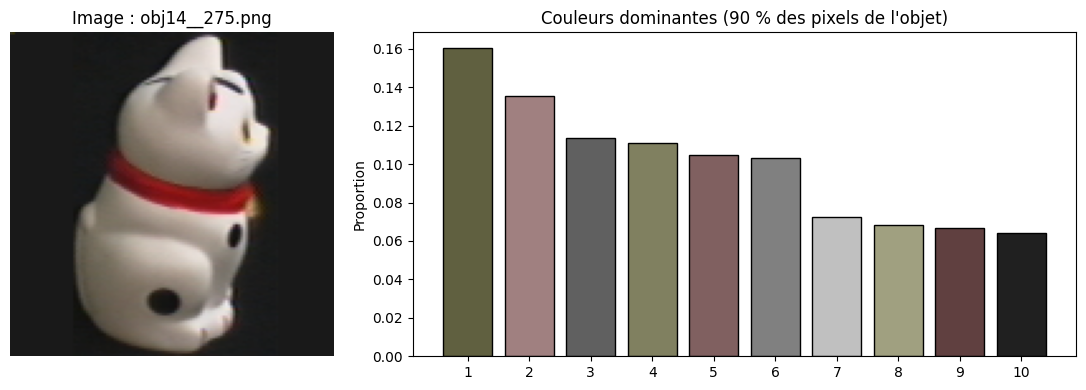

In [11]:
def couleurs_dominantes(rgb, masque, pas=PAS_QUANTIFICATION, couverture=COUVERTURE,
                        k_max=K_MAX):
    """Retourne les couleurs dominantes d'une image et leurs proportions.

    Paramètres
    ----------
    rgb : ndarray (H, W, 3)
        Image en RGB.
    masque : ndarray booléen (H, W)
        Pixels d'objet (True = objet).
    pas : int
        Pas de quantification par canal.
    couverture : float
        Proportion cumulée visée (0.90 = 90 %).
    k_max : int
        Nombre maximum de couleurs retournées.

    Retourne
    --------
    (couleurs, poids) :
        couleurs : ndarray (N, 3) des couleurs quantifiées
        poids    : ndarray (N,) des proportions, somme = 1
    """
    # 1) Quantification des pixels de l'objet uniquement
    pixels = rgb[masque]
    pixels_quantifies = (pixels // pas) * pas

    # 2) Comptage des occurrences de chaque couleur quantifiée
    couleurs, comptes = np.unique(pixels_quantifies, axis=0, return_counts=True)

    # 3) Tri par fréquence décroissante
    ordre = np.argsort(-comptes)
    couleurs = couleurs[ordre]
    comptes = comptes[ordre]

    # 4) Proportions et sélection cumulative jusqu'à la couverture voulue
    proportions = comptes / comptes.sum()
    cumul = np.cumsum(proportions)
    k = int(np.searchsorted(cumul, couverture) + 1)   # nombre de couleurs nécessaires
    k = min(k, k_max)                                 # plafonnement

    couleurs = couleurs[:k].astype(float)
    poids = proportions[:k]
    poids = poids / poids.sum()                       # renormalisation (somme = 1)
    return couleurs, poids


# --- Test sur une image ---
chemin_test = chemins[0]
rgb_test = charger_image(chemin_test)
masque_test = masque_objet(rgb_test)
coul_test, poids_test = couleurs_dominantes(rgb_test, masque_test)

print(f"Image test : {os.path.basename(chemin_test)}")
print(f"Nombre de couleurs dominantes retenues : {len(coul_test)}")
print(f"Couverture cumulée réelle : {poids_test.sum() * 100:.1f} % (renormalisée à 100 %)")
for (r, g, b), p in zip(coul_test, poids_test):
    print(f"   RGB = ({int(r):3d}, {int(g):3d}, {int(b):3d})  ->  {p * 100:5.1f} %")

# --- Affichage : image + bande des couleurs dominantes ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4),
                               gridspec_kw={"width_ratios": [1, 2]})

ax1.imshow(rgb_test)
ax1.set_title(f"Image : {os.path.basename(chemin_test)}")
ax1.axis("off")

# Bande de couleurs : une barre par couleur, hauteur = proportion
for i, ((r, g, b), p) in enumerate(zip(coul_test, poids_test)):
    ax2.bar(i, p, color=(r / 255, g / 255, b / 255), edgecolor="black")
ax2.set_xticks(range(len(coul_test)))
ax2.set_xticklabels([f"{i + 1}" for i in range(len(coul_test))])
ax2.set_ylabel("Proportion")
ax2.set_title("Couleurs dominantes (90 % des pixels de l'objet)")

plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_RESULTATS, "ex1_couleurs_dominantes.png"), dpi=120)
plt.show()


## Étape 3 — Mesure de distance entre deux images

### Le problème

Deux images n'ont pas forcément le **même nombre** de couleurs dominantes (l'une peut en avoir 4, l'autre 10). On ne peut donc pas faire une simple distance euclidienne entre deux vecteurs de tailles différentes.

### Solution : appariement glouton pondéré (version simplifiée de l'EMD)

On rapproche les couleurs deux à deux en tenant compte des **proportions** :

1. On cherche la paire (couleur de A, couleur de B) la **plus proche** en RGB.
2. On transfère le **maximum de poids commun** : $m = \min(w_A, w_B)$.
3. On **retire** ce poids des deux côtés (poids restants), ce qui évite de compter deux fois la même couleur.
4. On recommence avec les poids restants.
5. Le poids **non apparié** est pénalisé par la distance maximale possible.

### Formule

$$D(A,B) = \sum_{paires} m_{ij} \cdot \lVert c_i - c_j \rVert \; + \; \left(\sum w_A^{\text{restant}} + \sum w_B^{\text{restant}}\right) \cdot \sqrt{3}\cdot 255$$

### Propriétés

- $D(A,A) = 0$ (les couleurs s'apparient exactement).
- La distance est **symétrique**.
- Elle est bornée par $\sqrt{3}\cdot 255 \approx 441{,}7$ (distance maximale entre deux couleurs RGB).


In [12]:
MAX_DIST = np.sqrt(3) * 255   # distance RGB maximale possible (~441.67)


def distance_couleurs(couleurs_a, poids_a, couleurs_b, poids_b):
    """Distance pondérée entre deux ensembles de couleurs dominantes.

    Appariement glouton : on associe à chaque étape les deux couleurs les plus
    proches, en transférant le maximum de poids commun. Les poids restants
    (non appariés) sont pénalisés par la distance maximale possible.
    """
    restant_a = poids_a.astype(float).copy()
    restant_b = poids_b.astype(float).copy()

    total = 0.0
    # On effectue au plus autant d'appariements qu'il y a de couleurs
    for _ in range(min(len(couleurs_a), len(couleurs_b))):
        i = int(np.argmax(restant_a))   # couleur de A ayant le plus de poids restant
        j = int(np.argmax(restant_b))   # couleur de B ayant le plus de poids restant

        # Poids commun transférable
        m = min(restant_a[i], restant_b[j])
        if m <= 0:
            break

        # Contribution : poids commun x distance RGB entre les deux couleurs
        distance_rgb = np.linalg.norm(couleurs_a[i] - couleurs_b[j])
        total += m * distance_rgb

        # On retire le poids déjà apparié (évite de compter deux fois)
        restant_a[i] -= m
        restant_b[j] -= m

    # Poids non appariés -> pénalité maximale
    total += (restant_a.sum() + restant_b.sum()) * MAX_DIST
    return total


# --- Vérifications rapides ---
coul_a, poids_a = couleurs_dominantes(charger_image(chemins[0]),
                                      masque_objet(charger_image(chemins[0])))
coul_b, poids_b = couleurs_dominantes(charger_image(chemins[1]),
                                      masque_objet(charger_image(chemins[1])))

print(f"Distance(A, A) = {distance_couleurs(coul_a, poids_a, coul_a, poids_a):.6f}  (attendu : 0)")
print(f"Distance(A, B) = {distance_couleurs(coul_a, poids_a, coul_b, poids_b):.6f}")
print(f"Distance(B, A) = {distance_couleurs(coul_b, poids_b, coul_a, poids_a):.6f}  (attendu : identique)")
print(f"Distance maximale théorique = {MAX_DIST:.2f}")


Distance(A, A) = 0.000000  (attendu : 0)
Distance(A, B) = 122.448017
Distance(B, A) = 122.448017  (attendu : identique)
Distance maximale théorique = 441.67


## Étape 4 — Matrice de similarité

On calcule la **matrice de distances** $D$ (taille $N \times N$, symétrique, diagonale nulle), puis on la transforme en **matrice de similarité** :

$$S(i,j) = 1 - \frac{D(i,j)}{\sqrt{3}\cdot 255}$$

### Pourquoi cette normalisation ?

On divise par la **distance maximale théorique** ($\sqrt{3}\cdot 255$), et non par le maximum observé sur le jeu d'images. Ainsi :

- $S = 1$ signifie « images identiques » ;
- $S = 0$ signifie « images aussi différentes que possible » ;
- les valeurs restent **comparables** d'un jeu d'images à l'autre (et avec l'exercice 2).


In [13]:
# --- Calcul des descripteurs de toutes les images ---
descripteurs = []
for chemin in chemins:
    rgb = charger_image(chemin)
    masque = masque_objet(rgb)
    couleurs, poids = couleurs_dominantes(rgb, masque)
    descripteurs.append((couleurs, poids))

print(f"{len(descripteurs)} descripteurs calculés "
      f"(de {min(len(d[0]) for d in descripteurs)} à "
      f"{max(len(d[0]) for d in descripteurs)} couleurs par image).\n")

# --- Matrices de distance et de similarité ---
n = len(chemins)
matrice_distance = np.zeros((n, n))
matrice_similarite = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if i == j:
            continue   # diagonale = 0
        d = distance_couleurs(descripteurs[i][0], descripteurs[i][1],
                              descripteurs[j][0], descripteurs[j][1])
        matrice_distance[i, j] = d
        matrice_similarite[i, j] = 1.0 - d / MAX_DIST

# Diagonale : une image est identique à elle-même
np.fill_diagonal(matrice_similarite, 1.0)

# --- Affichage de la matrice de similarité ---
largeur = 16
entete = "Image".ljust(largeur) + "".join(nom[:13].ljust(14) for nom in noms_images)
print(entete)
print("-" * len(entete))
for i, nom in enumerate(noms_images):
    ligne = nom[:15].ljust(largeur)
    ligne += "".join(f"{matrice_similarite[i, j]:.3f}".ljust(14) for j in range(n))
    print(ligne)


12 descripteurs calculés (de 10 à 10 couleurs par image).

Image           obj14__275.pn obj14__330.pn obj14__60.png obj16__245.pn obj16__5.png  obj16__70.png obj1__180.png obj1__40.png  obj1__95.png  obj27__125.pn obj27__190.pn obj27__275.pn 
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
obj14__275.png  1.000         0.723         0.669         0.713         0.669         0.768         0.494         0.508         0.493         0.544         0.547         0.465         
obj14__330.png  0.723         1.000         0.700         0.715         0.710         0.725         0.475         0.526         0.493         0.509         0.533         0.534         
obj14__60.png   0.669         0.700         1.000         0.681         0.634         0.598         0.415         0.410         0.482         0.425         0.456         0.452         
obj16__245.png  

## Étape 5 — Visualisation et classement

- Une **heatmap** permet de repérer visuellement les blocs d'images similaires (couleurs chaudes = forte similarité).
- Le **classement des paires** donne les couples d'images les plus proches.

Les résultats sont enregistrés dans `seance 4/resultats/` :
- `ex1_matrice_similarite.png` (heatmap)
- `ex1_matrice_similarite.csv` (matrice numérique)


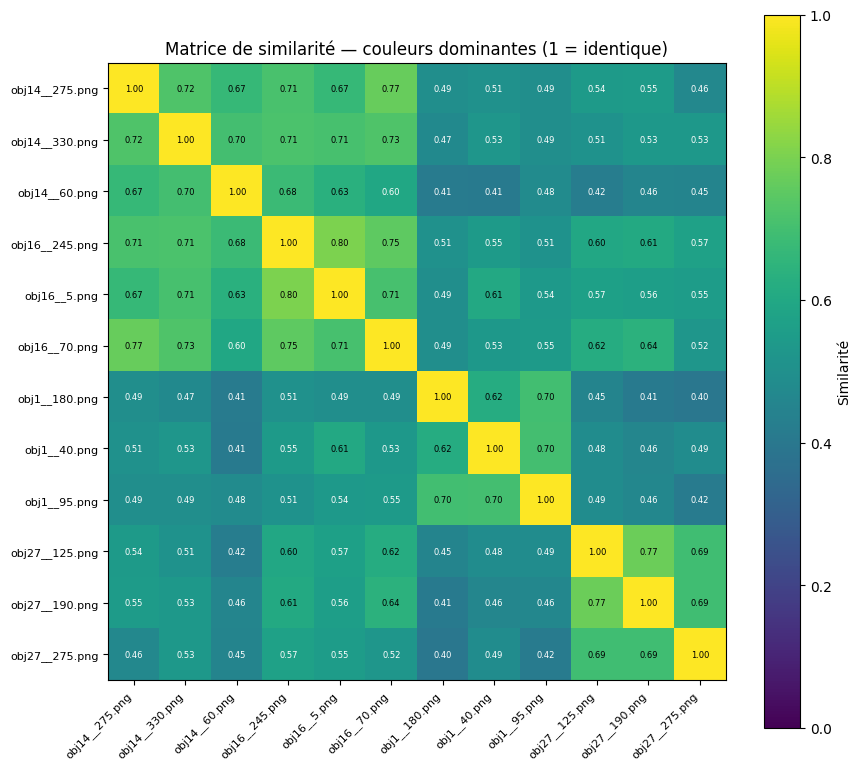

Matrice sauvegardée dans : .\resultats\ex1_matrice_similarite.csv

Les 10 paires d'images les plus similaires :
   1.  80.3 %   obj16__245.png  <->  obj16__5.png
   2.  77.5 %   obj27__125.png  <->  obj27__190.png
   3.  76.8 %   obj14__275.png  <->  obj16__70.png
   4.  75.2 %   obj16__245.png  <->  obj16__70.png
   5.  72.5 %   obj14__330.png  <->  obj16__70.png
   6.  72.3 %   obj14__275.png  <->  obj14__330.png
   7.  71.5 %   obj14__330.png  <->  obj16__245.png
   8.  71.3 %   obj14__275.png  <->  obj16__245.png
   9.  71.0 %   obj16__5.png  <->  obj16__70.png
  10.  71.0 %   obj14__330.png  <->  obj16__5.png

Similarité moyenne à l'intérieur d'un objet vs meilleure similarité externe
Objet      intra (moy.)   externe (max)      écart
obj1              0.672           0.605     +0.067
obj14             0.697           0.768     -0.071
obj16             0.755           0.768     -0.013
obj27             0.720           0.643     +0.078


In [14]:
# --- Heatmap de la matrice de similarité ---
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(matrice_similarite, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(noms_images, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(noms_images, fontsize=8)
ax.set_title("Matrice de similarité — couleurs dominantes (1 = identique)")
fig.colorbar(image, ax=ax, label="Similarité")

# Annotation des valeurs
for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{matrice_similarite[i, j]:.2f}", ha="center", va="center",
                fontsize=6, color="white" if matrice_similarite[i, j] < 0.6 else "black")

plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_RESULTATS, "ex1_matrice_similarite.png"), dpi=130)
plt.show()

# --- Sauvegarde CSV ---
chemin_csv = os.path.join(DOSSIER_RESULTATS, "ex1_matrice_similarite.csv")
with open(chemin_csv, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["Image"] + noms_images)
    for i, nom in enumerate(noms_images):
        writer.writerow([nom] + [f"{matrice_similarite[i, j]:.6f}" for j in range(n)])
print(f"Matrice sauvegardée dans : {chemin_csv}\n")

# --- Classement des paires les plus similaires (hors diagonale) ---
paires = []
for i in range(n):
    for j in range(i + 1, n):
        paires.append((matrice_similarite[i, j], noms_images[i], noms_images[j]))
paires.sort(reverse=True)

print("Les 10 paires d'images les plus similaires :")
for rang, (sim, a, b) in enumerate(paires[:10], start=1):
    print(f"  {rang:2d}. {sim * 100:5.1f} %   {a}  <->  {b}")

# --- Statistiques intra-objet / inter-objets ---
# Le nom de l'objet est la partie avant "__" : obj1, obj14, obj16, obj27
groupes = [nom.split("__")[0] for nom in noms_images]

print("\n" + "=" * 78)
print("Similarité moyenne à l'intérieur d'un objet vs meilleure similarité externe")
print("=" * 78)
print(f"{'Objet':8s} {'intra (moy.)':>14s} {'externe (max)':>15s} {'écart':>10s}")
for groupe in sorted(set(groupes)):
    dedans = [i for i, g in enumerate(groupes) if g == groupe]
    dehors = [i for i, g in enumerate(groupes) if g != groupe]

    intra = np.mean([matrice_similarite[i, j] for i in dedans for j in dedans if i < j])
    externe = matrice_similarite[np.ix_(dedans, dehors)].max()

    print(f"{groupe:8s} {intra:14.3f} {externe:15.3f} {intra - externe:+10.3f}")


## Étape 6 — Analyse et discussion

### Résultats obtenus

**Paires les plus similaires :**

| Rang | Similarité | Paire |
|---|---|---|
| 1 | 80.3 % | `obj16__245` ↔ `obj16__5` |
| 2 | 77.5 % | `obj27__125` ↔ `obj27__190` |
| 3 | 76.8 % | `obj14__275` ↔ `obj16__70` |
| 4 | 75.2 % | `obj16__245` ↔ `obj16__70` |
| 5 | 72.5 % | `obj14__330` ↔ `obj16__70` |
| 6 | 72.3 % | `obj14__275` ↔ `obj14__330` |

**Similarité intra-objet vs meilleure similarité externe :**

| Objet | Intra (moy.) | Externe (max) | Écart |
|---|---|---|---|
| `obj1` (boîte jaune) | 0.672 | 0.605 | **+0.067** |
| `obj14` (chat blanc) | 0.697 | 0.768 | **−0.071** |
| `obj16` (pot blanc) | 0.755 | 0.768 | **−0.013** |
| `obj27` (voiture verte) | 0.720 | 0.643 | **+0.078** |

### Interprétation

- **`obj1` et `obj27` sont bien séparés** : leur couleur dominante est très typée (jaune/orangé pour la boîte, vert pour la voiture). L'écart intra/inter est nettement positif (+0.067 et +0.078).
- **`obj14` et `obj16` sont confondus** : le chat et le pot partagent une grande surface **blanche / gris clair**. Leurs descripteurs ne diffèrent que par la petite zone colorée (collier rouge, fleurs multicolores, intérieur rose), qui pèse peu dans les 90 % de couverture. Résultat : `obj14__275` ↔ `obj16__70` (76.8 %) est plus forte que `obj14__275` ↔ `obj14__60` (66.9 %).
- **`obj16` est très homogène** (0.755 en moyenne) : les trois vues du pot sont prises sous des angles proches avec le même éclairage.
- **`obj14__60` est la vue la plus atypique** : sa similarité avec les autres vues du chat tombe à 0.67–0.70, car l'objet y occupe une surface plus petite et le fond résiduel pèse davantage dans les proportions.
- **Les scores restent modérés (0.40 → 0.80)** : la normalisation par la distance maximale théorique ($\sqrt{3}\cdot255$) est volontairement sévère. Elle rend les valeurs comparables entre jeux d'images, mais aucune paire n'atteint 1 (les couleurs quantifiées ne coïncident jamais exactement).

### Limites de la méthode

1. **Perte de l'information spatiale** : la position et la disposition des couleurs ne sont pas prises en compte. Un objet blanc sur fond rouge et l'inverse auraient le même descripteur.
2. **Sensibilité à la quantification** : le pas de 32 regroupe les couleurs proches mais fusionne parfois deux teintes distinctes (deux verts différents deviennent identiques).
3. **Sensibilité au masque du fond** : une tolérance trop grande retire des pixels de l'objet, une tolérance trop faible laisse du fond. La tolérance de 20 a été validée visuellement à l'étape 1.
4. **Plafond `K_MAX = 10`** : au-delà de 10 couleurs, on perd de l'information. Sans plafond, certaines images demandaient plus de 40 couleurs, ce qui rendait la comparaison instable.
5. **Éclairage** : les variations de luminosité entre deux vues modifient les couleurs quantifiées (une même surface blanche peut tomber dans `[160,160,160]` ou `[192,192,192]`).
6. **Objets uniformes** : la méthode est peu discriminante lorsque plusieurs objets partagent une dominante chromatique.

### Améliorations possibles

- Passer en espace **HSV** ou **Lab** pour séparer la teinte de la luminosité et rendre la méthode plus robuste à l'éclairage.
- Utiliser un **EMD exact** (programmation linéaire) au lieu de l'appariement glouton.
- Pondérer les couleurs par leur **saturation** pour donner plus de poids aux zones colorées qu'aux zones blanches/grises.
- Ajouter une information de **position** (histogramme par blocs, comme en séance 3) pour distinguer deux objets de même couleur mais de structure différente.

### Conclusion

La méthode des couleurs dominantes **fonctionne bien pour les objets à couleur typée** (`obj1`, `obj27`) mais **échoue à distinguer deux objets de même teinte dominante** (`obj14` / `obj16`). C'est une limite intrinsèque de tout descripteur purement colorimétrique global : elle justifie l'utilisation de descripteurs plus riches (histogrammes par blocs, texture de Tamura) dans les exercices suivants.
